In [9]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from pathlib import Path
from scipy.spatial import cKDTree
import seaborn as sns
from utils import pq_to_xy
from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
pd.set_option('display.max_rows', 200)

In [10]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

In [11]:

def hex_distance(dp, dq):
    return np.maximum.reduce([
        np.abs(dp),
        np.abs(dq),
        np.abs(dq - dp)
    ])


def hex_offsets(radius):
    rows = []

    for dp in range(-radius, radius + 1):
        for dq in range(-radius, radius + 1):
            if hex_distance(dp, dq) <= radius:
                rows.append((dp, dq))

    return pd.DataFrame(rows, columns=["dp", "dq"])


def mean_spatial_kernel_zero_filled(
    edges,
    pre_type="Mi1",
    post_type="T4b",
    same_side=True,
    radius=3
):
    df = edges.query(
        "pre_cell_type == @pre_type and post_cell_type == @post_type"
    ).copy()

    if same_side:
        df = df.query("pre_side == post_side").copy()

    df["signed_count"] = df["count"] * df["sign"]

    offsets = hex_offsets(radius)

    if post_type == "CT1":
        # Treat CT1 as many local column compartments.
        # Each CT1 target column acts like a pseudo-postsynaptic unit.
        post_cells = (
            df[["target_p", "target_q", "post_side"]]
            .dropna(subset=["target_p", "target_q"])
            .drop_duplicates()
            .copy()
            .rename(columns={
                "target_p": "ct1_target_p",
                "target_q": "ct1_target_q",
            })
        )

        post_cells["pseudo_post"] = (
            post_cells["ct1_target_p"].astype(int).astype(str)
            + "_"
            + post_cells["ct1_target_q"].astype(int).astype(str)
        )

        full_index = (
            post_cells[["pseudo_post", "post_side"]]
            .assign(key=1)
            .merge(offsets.assign(key=1), on="key")
            .drop(columns="key")
        )

        observed = (
            df
            .dropna(subset=["target_p", "target_q", "dp", "dq"])
            .assign(
                pseudo_post=lambda d: (
                    d["target_p"].astype(int).astype(str)
                    + "_"
                    + d["target_q"].astype(int).astype(str)
                ),
                dp=lambda d: d["dp"].astype(int),
                dq=lambda d: d["dq"].astype(int),
            )
            .groupby(["pseudo_post", "dp", "dq"], as_index=False)
            .agg(
                count=("count", "sum"),
                signed_count=("signed_count", "sum"),
            )
        )

        full = full_index.merge(
            observed,
            on=["pseudo_post", "dp", "dq"],
            how="left"
        )

    else:
        # Original behavior: normalize over postsynaptic cells
        post_cells = (
            edges.query("post_cell_type == @post_type")
            [["post", "target_p", "target_q", "post_side"]]
            .drop_duplicates()
            .copy()
        )

        if same_side:
            post_cells = post_cells[
                post_cells["post_side"].isin(df["post_side"].dropna().unique())
            ]

        full_index = (
            post_cells.assign(key=1)
            .merge(offsets.assign(key=1), on="key")
            .drop(columns="key")
        )

        observed = (
            df
            .dropna(subset=["dp", "dq"])
            .assign(
                dp=lambda d: d["dp"].astype(int),
                dq=lambda d: d["dq"].astype(int),
            )
            .groupby(["post", "dp", "dq"], as_index=False)
            .agg(
                count=("count", "sum"),
                signed_count=("signed_count", "sum")
            )
        )

        full = full_index.merge(
            observed,
            on=["post", "dp", "dq"],
            how="left"
        )

    full["count"] = full["count"].fillna(0)
    full["signed_count"] = full["signed_count"].fillna(0)

    kernel = (
        full
        .groupby(["dp", "dq"], as_index=False)
        .agg(
            mean_count=("count", "mean"),
            mean_signed_count=("signed_count", "mean")
        )
        .sort_values("mean_signed_count", ascending=False)
    )

    return kernel, full

mi1_t4b_kernel, mi1_t4b_full = mean_spatial_kernel_zero_filled(
    edges,
    pre_type="CT1",
    post_type="T5b")

mi1_t4b_kernel

,dp,dq,mean_count,mean_signed_count
0,-3,-3,0.000000,0.000000
1,-3,-2,0.000000,0.000000
3,-3,0,0.000000,0.000000
4,-2,-3,0.000000,0.000000
10,-1,-2,0.000000,0.000000
33,3,0,0.000000,0.000000
9,-1,-3,0.000000,0.000000
15,0,-3,0.000000,0.000000
16,0,-2,0.000000,0.000000
17,0,-1,0.000000,0.000000


<Axes: title={'center': 'Mi1 to T4b mean signed synapse count'}>

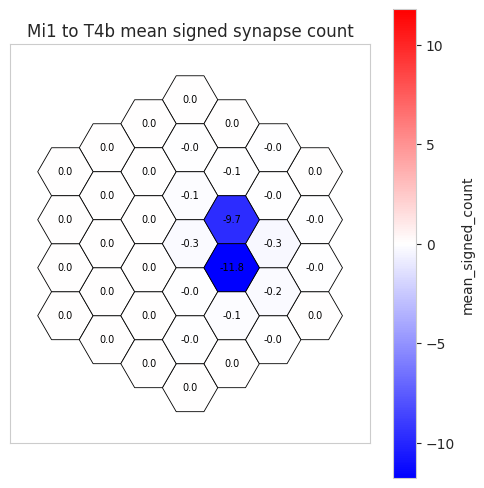

In [12]:
from matplotlib.patches import RegularPolygon
from matplotlib.colors import Normalize
import matplotlib.pyplot as plt
import numpy as np

    

def plot_spatial_kernel_hex(
    kernel,
    value_col="mean_signed_syn_count",
    *,
    radius=None,
    hexsize=1.0,
    cmap="bwr",
    norm=None,
    mirror_x=False,
    mirror_y=False,
    plot_labels=True,
    title=None,
    ax=None,
    add_colorbar=False,
    fs=14
):
    """
    Plot mean spatial kernel using dp/dq as relative hex coordinates.
    Red = positive signed synapses
    Blue = negative signed synapses
    White = zero
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    else:
        fig = ax.figure
        
    kernel = kernel.copy()

    kernel = kernel.dropna(subset=["dp", "dq", value_col])
    kernel["dp"] = kernel["dp"].astype(int)
    kernel["dq"] = kernel["dq"].astype(int)

    if radius is not None:
        dist = hex_distance(kernel["dp"], kernel["dq"])
        kernel = kernel[dist <= radius].copy()

    ax.set_aspect("equal")

    cmap_obj = plt.get_cmap(cmap)

    if norm is None:
        vmax = np.nanmax(np.abs(kernel[value_col].to_numpy()))
        norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

    x, y = pq_to_xy(
        kernel["dp"].to_numpy(),
        kernel["dq"].to_numpy(),
        hexsize=hexsize
    )

    if mirror_x:
        x = -x
    if mirror_y:
        y = -y

    vals = kernel[value_col].to_numpy()

    for xi, yi, dp, dq, val in zip(
        x, y,
        kernel["dp"].to_numpy(),
        kernel["dq"].to_numpy(),
        vals
    ):
        ax.add_patch(
            RegularPolygon(
                (xi, yi),
                numVertices=6,
                radius=hexsize,
                orientation=np.pi / 6,
                facecolor=cmap_obj(norm(val)),
                edgecolor="black",
                linewidth=0.6
            )
        )

        if plot_labels:
            ax.text(
                xi, yi,
                # f"{dp},{dq}\n{val:.1f}",
                f"{val:.1f}",
                fontsize=7,
                ha="center",
                va="center",
                color="black"
            )

    pad = 2 * hexsize
    ax.set_xlim(x.min() - pad, x.max() + pad)
    ax.set_ylim(y.min() - pad, y.max() + pad)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

    if title is None:
        title = value_col
    ax.set_title(title)

    if add_colorbar:
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        fig.colorbar(sm, ax=ax, label=value_col)
    
    fig.tight_layout()

    return ax

# plot_spatial_kernel_hex(mi1_t4b_kernel, value_col="mean_signed_count", radius=4, cmap="bwr", title="Mi1 to T4b mean signed synapse count")

plot_spatial_kernel_hex(mi1_t4b_kernel, value_col="mean_signed_count", 
                        radius=4, cmap="bwr", add_colorbar=True,
                        title="Mi1 to T4b mean signed synapse count")